In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os
import scipy.stats
import ast
import warnings

warnings.filterwarnings('ignore')

# Set pandas display options for better output visibility
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 20)

# Helpers

In [2]:
def get_main_df(path, method, trial_name='0.csv'):
    df_path = os.path.join(path, method, trial_name)
    df = pd.read_csv(df_path)
    return df

def _add_averaged_stats(metrics, name, values):
    '''
    Stores mean plus three alternative spread measures for `values` (a column over
    successful problems), used by plot_stratified_metrics(spread_style=...):
      <name>       -- mean
      <name>_std           -- linear sample std (ddof=1); "variance" spread_style
      <name>_log_lower/upper -- expm1(log1p(mean) +/- std(log1p(x))), i.e. a band that
        is symmetric in log1p-space and centered on the same arithmetic mean that gets
        plotted (NOT on expm1(mean(log1p(x))), which is closer to the geometric mean --
        for skewed data that point sits well below the plotted mean by Jensen's
        inequality, which would decenter the band from the line it's drawn around).
        log1p/expm1 (not log/exp) so a value of exactly 0 (e.g. zero refinement
        failures) is handled without -inf. "log_variance" spread_style.
      <name>_p25/p75       -- 25th/75th percentile (IQR); "percentile" spread_style.
    Symmetric mean +/- std looks wrong on the log-scaled axes these metrics are usually
    plotted on: a fixed linear std maps to a visually longer whisker below the mean than
    above it, and can even go negative for skewed positive-only data (times, counts).
    The log and percentile variants stay within the data's own range and look symmetric
    on a log axis.
    '''
    mean = values.mean()
    metrics[name] = mean
    metrics[f'{name}_std'] = values.std()
    log_std = np.log1p(values).std()
    log_center = np.log1p(mean)
    metrics[f'{name}_log_lower'] = np.expm1(log_center - log_std)
    metrics[f'{name}_log_upper'] = np.expm1(log_center + log_std)
    metrics[f'{name}_p25'] = values.quantile(0.25)
    metrics[f'{name}_p75'] = values.quantile(0.75)

def _add_nan_averaged_stats(metrics, name):
    for suffix in ('', '_std', '_log_lower', '_log_upper', '_p25', '_p75'):
        metrics[f'{name}{suffix}'] = float('nan')

def compute_main_metrics(df, global_success_mask=None):
    '''
    Success rate: successful problems / total problems
    Avg refinement failures per problem
    Average Planning time: 
    If global_success_mask is provided, averages are computed only over rows where all methods succeed.

    Every averaged metric also gets spread columns (see _add_averaged_stats) that feed
    the optional variance decoration in plot_stratified_metrics. success_rate only gets
    the standard error of the proportion (`success_rate_std`) -- it's a rate over all
    problems, not a mean over a column of successful-problem values, so the log/
    percentile variants don't apply to it.
    '''
    metrics = {}

    n = len(df)
    metrics['success_rate'] = df['success'].apply(lambda x: 1 if x else 0).sum() / n
    p = metrics['success_rate']
    metrics['success_rate_std'] = (p * (1 - p) / n) ** 0.5 if n > 0 else float('nan')
    success_mask = df['success'] == 1

    # If a global_success_mask is provided, also filter on that mask
    if global_success_mask is not None:
        filtered_success_mask = success_mask & global_success_mask.reset_index(drop=True)
    else:
        filtered_success_mask = success_mask

    successful_df = df[filtered_success_mask]
    
    if len(successful_df) > 0:
        _add_averaged_stats(metrics, 'ref_failures', successful_df['iterations'])
        _add_averaged_stats(metrics, 'avg_planning_time', successful_df['planning'])
        _add_averaged_stats(metrics, 'avg_process_time', successful_df['process'])
        _add_averaged_stats(metrics, 'avg_total_time', successful_df['total'])
        # `prompting` is normalized in compute_full_metrics: it is 0 for methods that
        # never call a VLM, and 0 for VLMB (whose prompting time counts as planning time),
        # so this subtraction is a no-op for everything except VIZ-COAST.
        total_no_prompting = successful_df['total'] - successful_df['prompting']
        _add_averaged_stats(metrics, 'avg_total_time_no_prompting', total_no_prompting)
    else:
        _add_nan_averaged_stats(metrics, 'ref_failures')
        _add_nan_averaged_stats(metrics, 'avg_planning_time')
        _add_nan_averaged_stats(metrics, 'avg_process_time')
        _add_nan_averaged_stats(metrics, 'avg_total_time')
        _add_nan_averaged_stats(metrics, 'avg_total_time_no_prompting')

    return metrics

def compute_full_metrics(main_path, methods, stratfication_function, file_ids=None, global_success=None):
    dfs = {}
    for method in methods:
        # global metrics    
        if file_ids is not None:
            this_df = get_main_df(main_path, method, file_ids[method])
        else:
            this_df = get_main_df(main_path, method)
        
        # join dfs 
        dfs[method] = this_df

    if global_success is not None:
        # compute global success mask: rows for which all methods succeed
        joined_df = pd.concat([df["success"] for df in dfs.values()], axis=1)
        if type(global_success) == bool:
            # all methods must succeed
            global_success_mask = joined_df.apply(lambda row: all(row == 1), axis=1)
        elif type(global_success) == int:
            # alternatively, mask for rows where atleast N methods succeed
            global_success_mask = joined_df.apply(lambda row: row.sum() >= global_success, axis=1)
        else:
            raise ValueError("global_success must be a boolean or an integer")

    full_metrics = {}
    for method in methods:
        full_metrics[method] = {}
        df = dfs[method]
        # VLMB planning time == prompting time
        if method == 'VLMB':
            df["planning"] = df["prompting"]
            # VLMB's prompting time has been re-labelled as its planning time, so there
            # is nothing left to strip out of its "total time excluding prompting".
            df["prompting"] = 0.0
        elif "prompting" not in df.columns:
            # methods that never call a VLM spend no time prompting
            df["prompting"] = 0.0

        metrics = compute_main_metrics(df)
        full_metrics[method]['global'] = metrics

        # stratified metrics
        strat_source_column = "num_blocks"
        if "num_goals" in df.columns:
            strat_source_column = "num_goals" # hardcoded for containers
        elif "num_items" in df.columns:
            strat_source_column = "num_items" # hardcoded for rack
        elif "num_ingredients" in df.columns:
            strat_source_column = "num_ingredients" # hardcoded for cooking
        
        df["stratification"] = df[strat_source_column].apply(lambda x: stratfication_function(x))
        metrics_by_packables = df.groupby("stratification").apply(compute_main_metrics, global_success_mask=global_success_mask)
        metrics_df = metrics_by_packables.apply(pd.Series)
        metrics_df = metrics_df.reset_index()
        full_metrics[method]['stratified'] = metrics_df
        # keep the normalized per-run rows around for per-problem (unaggregated) plots
        full_metrics[method]['raw'] = df

    return full_metrics

# Fixed per-method style. Each method always keeps the same color/marker regardless of
# where it sits in a domain's `methods` list, so reordering `methods` in a domain cell
# changes ONLY the draw order: earlier in the list is drawn first (underneath), later
# entries are drawn on top of it.
METHOD_STYLES = {
    "coast_fd":             ("blue",   "o"),
    "coast_z3":             ("red",    "s"),
    "incremental":          ("brown",  "^"),
    "VLMB":                 ("purple", "D"),
    "VIZ-COAST":            ("green",  "P"),
    "VIZ-COAST-nofeedback": ("orange", "X"),
    "vc_nofeedback":        ("orange", "X"),
}

# Everything that can be plotted, and the title drawn above its subplot. Pass any subset
# of these keys as `metrics=` to plot_stratified_metrics.
METRIC_LABELS = {
    "success_rate": "Success Rate(%)",
    "ref_failures": "Ref. Failures",
    "avg_planning_time": "Planning Time(s)",
    "avg_process_time": "Grounding Time(s)",
    "avg_total_time": "Total Time(s)",
    "avg_total_time_no_prompting": "Total Time w/o Prompting(s)",
}

# Legend name for each method, shared by the aggregate and the per-problem plots.
METHOD_LABELS = {
    "coast_fd": "COAST+FD",
    "coast_z3": "COAST+Z3",
    "incremental": "Incremental",
    "VLMB": "VLM Only",
    "VIZ-COAST": "VIZ-COAST",
    # "vc_madag": "VIZ-COAST-MADAG",
    # "vc_satplan": "VIZ-COAST-SATPLAN",
    "VIZ-COAST-nofeedback": "No feedback",
}

# X-axis label for each domain's stratification, shared by the aggregate and the
# per-problem plots.
X_AXIS_LABELS = {
    "num_blocks": "# Blocks",
    "num_goals": "# Goals",
    "num_packables": "# Packables",
    "num_items": "# Items",
    "num_ingredients": "# Ingredients",
}

# Plotted when `metrics` is not passed.
DEFAULT_METRICS = ["success_rate", "ref_failures", "avg_planning_time"]

# Width of one subplot, picked so the 3 default metrics reproduce the original (28, 10).
SUBPLOT_WIDTH = 28 / 3

# How far apart (in x data units) the "errorbar_offset" style nudges each method's
# error bars, so overlapping bars at the same stratification value don't sit on top
# of each other. Centered on 0 across methods (see the offset formula below). Only the
# error bars move -- the line/markers stay at the true x position.
VARIANCE_OFFSET_STEP = 0.15

# Valid values for plot_stratified_metrics(variance_style=...) -- how the spread is drawn.
VARIANCE_STYLES = ("errorbar", "band", "errorbar_offset")

# Valid values for plot_stratified_metrics(spread_style=...) -- what the spread means.
# See _add_averaged_stats for how each is computed.
SPREAD_STYLES = ("variance", "log_variance", "percentile")

def _spread_bounds(metrics_df, metric, spread_style):
    '''
    (lower, upper) Series for `metric` under `spread_style`, or None if metrics_df
    doesn't have the needed columns (e.g. success_rate only has "variance" bounds).
    '''
    mean = metrics_df[metric]
    if spread_style == "variance":
        std_col = f"{metric}_std"
        if std_col not in metrics_df.columns:
            return None
        return mean - metrics_df[std_col], mean + metrics_df[std_col]
    elif spread_style == "log_variance":
        lower_col, upper_col = f"{metric}_log_lower", f"{metric}_log_upper"
        if lower_col not in metrics_df.columns:
            return None
        return metrics_df[lower_col], metrics_df[upper_col]
    elif spread_style == "percentile":
        lower_col, upper_col = f"{metric}_p25", f"{metric}_p75"
        if lower_col not in metrics_df.columns:
            return None
        return metrics_df[lower_col], metrics_df[upper_col]
    else:
        raise ValueError(f"spread_style must be one of {SPREAD_STYLES}, got {spread_style!r}")

# plot all methods
def plot_stratified_metrics(
    full_metrics,
    stratification_title="num_blocks",
    custom_y_bounds=None,
    custom_legend_positions=None,
    linear_scale=None,
    metrics=None,
    show_variance=False,
    variance_style="errorbar",
    spread_style="variance",
    variance_methods=None,
):
    '''
    show_variance -- draw variance alongside the mean line. Pass True to show it for
    every metric, or an iterable of metric names (e.g. {"avg_planning_time"}) to show it
    only for those. The variance decoration itself is never added to the legend -- only
    the underlying mean line/marker is.

    variance_methods -- restrict which methods' lines get the variance decoration.
    None (default) means every method that show_variance/spread_style would otherwise
    show it for. Pass an iterable of method keys (the same strings used in the
    `methods` list passed to compute_full_metrics, e.g. {"VIZ-COAST", "coast_fd"}) to
    show it only for those methods; every other method still gets its plain mean line.

    variance_style -- one of VARIANCE_STYLES, how the spread is drawn:
      "errorbar" (default) -- vertical caps at each point
      "band" -- a translucent band behind the line
      "errorbar_offset" -- like "errorbar", but each method's error bars (not its
        line/markers) are nudged sideways by VARIANCE_OFFSET_STEP so overlapping bars
        from different methods at the same x don't sit on top of each other

    spread_style -- one of SPREAD_STYLES, what the spread bounds mean (see
    _add_averaged_stats for the exact computation):
      "variance" (default) -- mean +/- linear std
      "log_variance" -- a band symmetric in log1p-space, centered on the mean.
        Looks symmetric on a log-scaled axis and never goes negative, unlike
        "variance" -- prefer this over "variance" for metrics plotted on a log axis.
      "percentile" -- 25th-75th percentile (IQR) of the underlying per-problem values.
        Most robust to outliers/skew; always within the observed data range.
    '''
    if variance_style not in VARIANCE_STYLES:
        raise ValueError(f"variance_style must be one of {VARIANCE_STYLES}, got {variance_style!r}")
    if spread_style not in SPREAD_STYLES:
        raise ValueError(f"spread_style must be one of {SPREAD_STYLES}, got {spread_style!r}")
    # One subplot per requested metric, in the order given.
    if metrics is None:
        metrics = DEFAULT_METRICS
    metric_labels = METRIC_LABELS
    # colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]
    # markers = ["o", "s", "D", "P", "X", "H"]

    # Fallback cycle -- only used for methods that are not listed in METHOD_STYLES
    colors = ['blue', 'red', 'brown', 'purple', 'green', 'orange']
    markers = ['o', 's', '^', 'D', 'P', 'X']  # circle, square, triangle, diamond
    x_axis_labels = X_AXIS_LABELS
    method_labels = METHOD_LABELS
    n_methods = len(full_metrics)

    # Make everything larger, but reduce border width
    plt.rcParams.update({
        'font.size': 32,
        'axes.labelsize': 38,
        'axes.titlesize': 40,
        'xtick.labelsize': 32,
        'ytick.labelsize': 32,
        'legend.fontsize': 30,
        'legend.title_fontsize': 32,
        'lines.linewidth': 12,    # Default line width
        'lines.markersize': 28,  # Default marker size
    })

    fig, axarr = plt.subplots(
        1, len(metrics), figsize=(SUBPLOT_WIDTH * len(metrics), 10), squeeze=False
    )
    # fig, axarr = plt.subplots(3, 1, figsize=(12, 30), squeeze=False)
    for idx, metric in enumerate(metrics):
        ax = axarr[0, idx]
        # ax = axarr[idx, 0]
        # full_metrics keeps the insertion order of `methods`, so i is the list position
        for i, method in enumerate(full_metrics.keys()):
            metrics_df = full_metrics[method]['stratified']
            color, marker = METHOD_STYLES.get(
                method,
                (colors[i % len(colors)], markers[i % len(markers)])
            )
            if metric not in metrics_df.columns:
                continue
            want_variance = (
                (show_variance is True or (show_variance and metric in show_variance))
                and (variance_methods is None or method in variance_methods)
            )
            bounds = _spread_bounds(metrics_df, metric, spread_style) if want_variance else None
            use_variance = bounds is not None
            xs = metrics_df["stratification"]
            # "errorbar_offset" only nudges the error bar's x position -- the line and
            # its markers are always drawn at the true stratification value.
            error_xs = xs
            if use_variance and variance_style == "errorbar_offset":
                error_xs = xs + (i - (n_methods - 1) / 2) * VARIANCE_OFFSET_STEP
            if use_variance:
                lower, upper = bounds
            if use_variance and variance_style == "band":
                # no label -- the mean line below carries the legend entry
                ax.fill_between(
                    xs, lower, upper,
                    color=color,
                    alpha=0.2,
                    linewidth=0,
                    zorder=1 + i
                )
            ax.plot(
                xs,
                metrics_df[metric],
                color=color,
                marker=marker,
                label=method_labels.get(method, method),
                zorder=2 + i  # later in `methods` -> drawn on top
            )
            if use_variance and variance_style in ("errorbar", "errorbar_offset"):
                # asymmetric yerr: (mean - lower, upper - mean), clipped so a bound that
                # crosses the mean (shouldn't normally happen) can't draw a negative bar
                mean = metrics_df[metric]
                yerr = np.vstack([
                    (mean - lower).clip(lower=0),
                    (upper - mean).clip(lower=0),
                ])
                # fmt='none' + no label: draws only the error bars/caps, not another
                # line/marker, and keeps them out of the legend
                ax.errorbar(
                    error_xs,
                    mean,
                    yerr=yerr,
                    fmt='none',
                    ecolor=color,
                    capsize=10,
                    capthick=3,
                    elinewidth=3,
                    zorder=2 + i
                )
        ax.set_xlabel(x_axis_labels[stratification_title], fontsize=38)
        ax.set_title(metric_labels.get(metric, metric), fontsize=60)

        if custom_y_bounds is not None and metric in custom_y_bounds:
            ax.set_ylim(custom_y_bounds[metric])
        if linear_scale is not None and metric in linear_scale:
            # Make y-axis ticks sparser
            ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
        else:
            ax.set_yscale('symlog')
        # Make grid lines translucent (alpha)
        ax.grid(True, linewidth=3, alpha=0.3)
        if custom_legend_positions is not None and metric in custom_legend_positions:
            if custom_legend_positions[metric] is not None:
                ax.legend(loc=custom_legend_positions[metric], fontsize=32)
        else:
            if idx == 0:  # Show legend only once
                ax.legend(loc='best', fontsize=32)
        # increase tick params
        ax.tick_params(axis='both', which='major', labelsize=32, width=3, length=10)
        ax.spines['top'].set_linewidth(3)
        ax.spines['right'].set_linewidth(3)
        ax.spines['bottom'].set_linewidth(3)
        ax.spines['left'].set_linewidth(3)
    plt.tight_layout()
    plt.show()


In [110]:
# Per-problem view: one marker per problem, with no averaging inside a stratification
# bucket. Reads the per-run rows that compute_full_metrics stashes under 'raw', so the
# `prompting` normalization (0 for non-VLM methods and for VLMB) applies here too.

TIME_COLUMN_LABELS = {
    "total": "Total Time(s)",
    "total_no_prompting": "Total Time w/o Prompting(s)",
    "planning": "Planning Time(s)",
    "process": "Grounding Time(s)",
    "search": "Search Time(s)",
    "prompting": "Prompting Time(s)",
}

def get_time_series(df, time_column):
    # "total_no_prompting" is derived; every other label is a raw column
    if time_column == "total_no_prompting":
        return df["total"] - df["prompting"]
    return df[time_column]

def plot_per_problem_times(
    full_metrics,
    stratification_title="num_blocks",
    time_column="total",
    sort_by_stratification=True,
    linear_scale=False,
    custom_y_bounds=None,
    legend_position='best',
    mark_failures=True,
    figsize=(28, 10),
):
    '''
    Plot the time each individual problem took, one x position per problem.

    sort_by_stratification -- order problems by their stratification value (# blocks,
    # ingredients, ...) and draw a divider between groups, instead of using raw CSV
    row order.
    mark_failures -- overlay a black x on runs that did not succeed; their time is
    however long the run went before giving up, not a solve time.
    linear_scale -- draw the y axis linearly; times are log-scaled by default.
    '''
    metric_label = TIME_COLUMN_LABELS.get(time_column, time_column)

    # Every method ran the same problems in the same row order, so a single ordering
    # taken from the first method indexes all of them.
    reference = next(iter(full_metrics.values()))['raw']
    if sort_by_stratification:
        order = reference.sort_values("stratification", kind="stable").index
    else:
        order = reference.index
    positions = np.arange(len(order))

    # Fallback cycle -- only used for methods that are not listed in METHOD_STYLES
    colors = ['blue', 'red', 'brown', 'purple', 'green', 'orange']
    markers = ['o', 's', '^', 'D', 'P', 'X']
    method_labels = METHOD_LABELS

    fig, ax = plt.subplots(figsize=figsize)
    any_failures = False
    min_time = np.inf
    # full_metrics keeps the insertion order of `methods`, so i is the list position
    for i, (method, entry) in enumerate(full_metrics.items()):
        df = entry['raw'].loc[order]
        if time_column not in df.columns and time_column != "total_no_prompting":
            # not every method logs every phase (e.g. packing's coast_z3 has no
            # `process` column)
            print(f"{method}: no '{time_column}' column, skipping")
            continue
        times = get_time_series(df, time_column).to_numpy()
        min_time = min(min_time, times.min())
        color, marker = METHOD_STYLES.get(
            method,
            (colors[i % len(colors)], markers[i % len(markers)])
        )
        ax.plot(
            positions,
            times,
            color=color,
            marker=marker,
            label=method_labels.get(method, method),
            linewidth=3,
            markersize=14,
            alpha=0.85,
            zorder=2 + i  # later in `methods` -> drawn on top
        )
        if mark_failures:
            failed = (df["success"] != 1).to_numpy()
            any_failures = any_failures or failed.any()
            ax.scatter(
                positions[failed], times[failed],
                marker='x', s=500, linewidths=5, color='black', zorder=20 + i
            )
    if mark_failures and any_failures:
        # one proxy handle -- the per-method scatters above stay out of the legend
        ax.scatter([], [], marker='x', s=500, linewidths=5, color='black', label='Failed')

    if sort_by_stratification:
        # one tick per stratification group, at the group's centre, and a divider
        # between neighbouring groups
        strat = reference.loc[order, "stratification"].to_numpy()
        boundaries = np.flatnonzero(strat[1:] != strat[:-1]) + 1
        for boundary in boundaries:
            ax.axvline(boundary - 0.5, color='gray', linewidth=2, alpha=0.4, zorder=1)
        edges = np.concatenate(([0], boundaries, [len(strat)]))
        ax.set_xticks((edges[:-1] + edges[1:] - 1) / 2)
        ax.set_xticklabels([str(strat[edge]) for edge in edges[:-1]])
        x_label = X_AXIS_LABELS.get(stratification_title, stratification_title)
        ax.set_xlabel(f"Problem, grouped by {x_label}", fontsize=38)
    else:
        ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=15, integer=True))
        ax.set_xlabel("Problem", fontsize=38)

    ax.set_title(metric_label, fontsize=60)
    if custom_y_bounds is not None:
        ax.set_ylim(custom_y_bounds)
    if linear_scale:
        ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    else:
        # plain log keeps the whole axis useful; symlog is only needed if some time is
        # 0 (e.g. prompting time for a method that never calls a VLM)
        ax.set_yscale('log' if min_time > 0 else 'symlog')
    ax.grid(True, linewidth=3, alpha=0.3)
    if legend_position is not None:
        ax.legend(loc=legend_position, fontsize=32)
    ax.tick_params(axis='both', which='major', labelsize=32, width=3, length=10)
    for side in ['top', 'right', 'bottom', 'left']:
        ax.spines[side].set_linewidth(3)
    plt.tight_layout()
    plt.show()


# Shelf

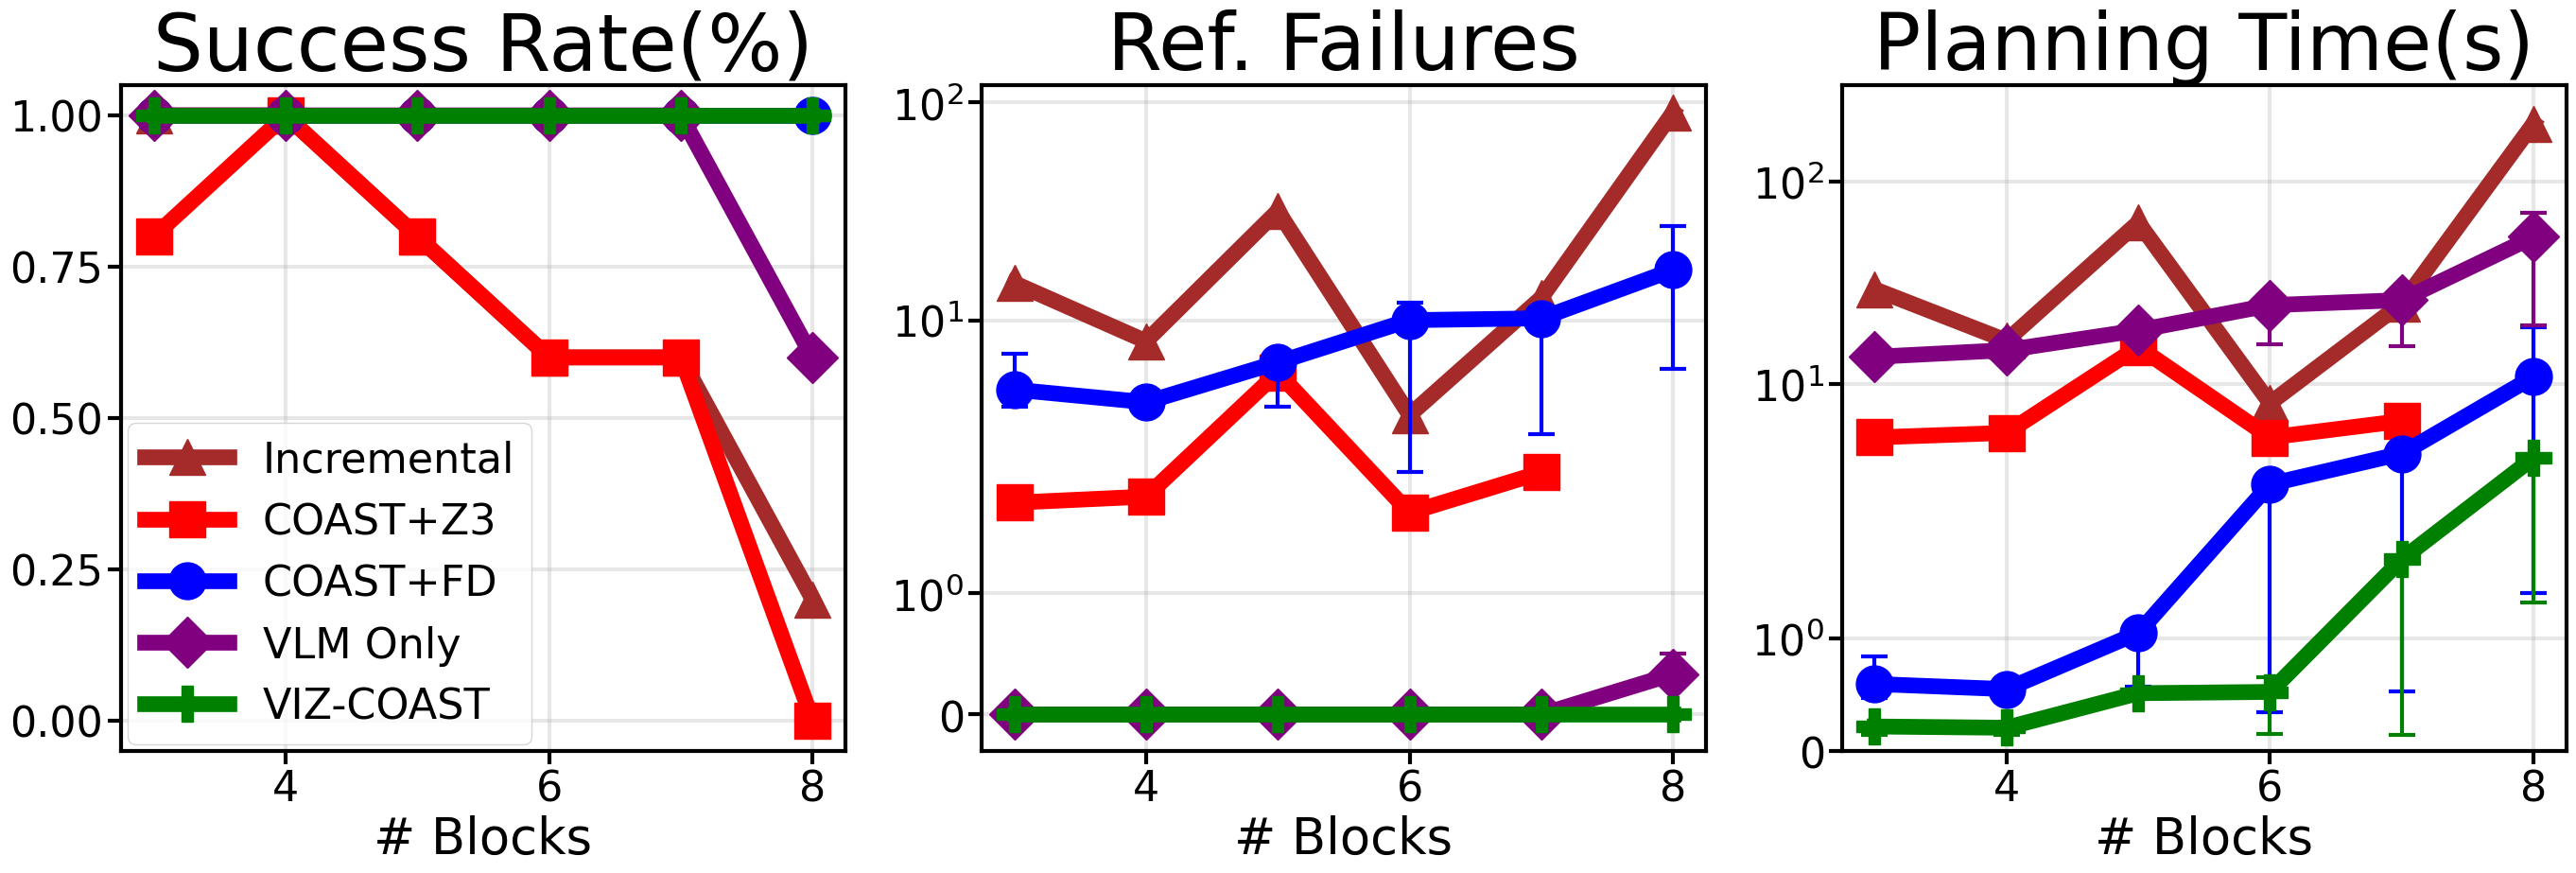

In [3]:
def get_num_blocks(num_blocks):
    return num_blocks

shelf_main_path = 'envs/shelf/main_table'
methods = ['incremental', 'coast_z3', 'coast_fd', 'VLMB', 'VIZ-COAST']
file_ids = {
    'coast_fd':'0.csv',
    'coast_z3':'0.csv',
    'incremental':'0.csv',
    'VLMB':'0.csv',
    'VIZ-COAST':'0.csv'
}

shelf_metrics = compute_full_metrics(shelf_main_path, methods, get_num_blocks, file_ids=file_ids, global_success=0)

custom_y_bounds = {
    "success_rate": [-0.05, 1.05],
    "ref_failures": [-0.3, 120],
    "avg_planning_time": [0.0, 300]
}
custom_legend_position = {
    "success_rate": (0.01, 0.01),
    "ref_failures": None,
    "avg_planning_time": None
}

plot_stratified_metrics(
    shelf_metrics,
    "num_blocks",
    custom_y_bounds=custom_y_bounds,
    custom_legend_positions=custom_legend_position,
    linear_scale=["success_rate"],
    metrics=["success_rate", "ref_failures", "avg_planning_time"],
    show_variance={"ref_failures", "avg_planning_time"},
    variance_methods={"coast_fd", "VIZ-COAST", "VLMB"},
    variance_style="errorbar",
    spread_style="percentile"
)

# Containers

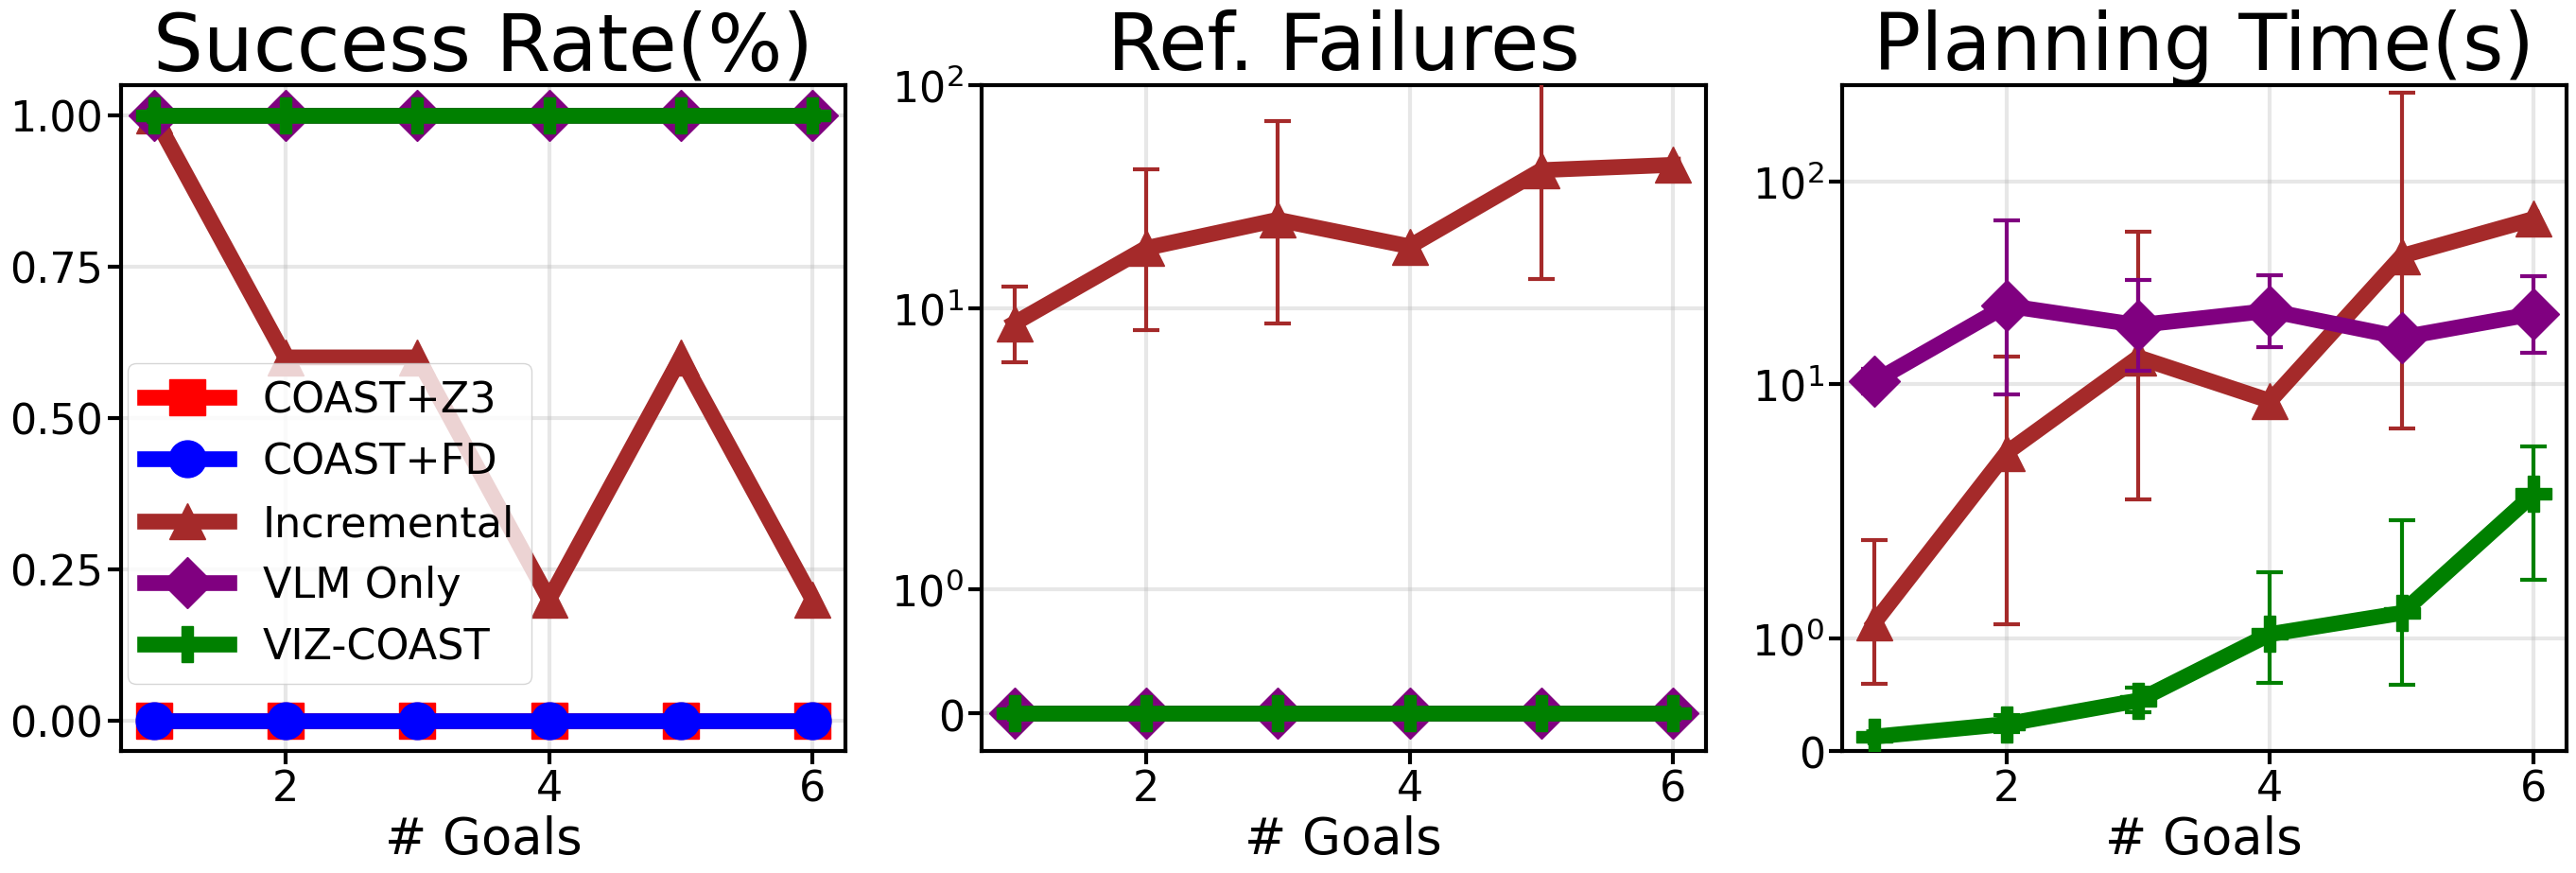

In [9]:
def get_num_goals(num_goals):
    return num_goals

containers_main_path = 'envs/containers/main_table'
methods = ['coast_z3', 'coast_fd', 'incremental', 'VLMB', 'VIZ-COAST']
file_ids = {
    'coast_fd':'0.csv',
    'coast_z3':'0.csv',
    'incremental':'0.csv',
    'VLMB':'0.csv',
    'VIZ-COAST':'0.csv'
}
containers_metrics = compute_full_metrics(containers_main_path, methods, get_num_goals, file_ids=file_ids, global_success=0)
custom_y_bounds = {
    "success_rate": [-0.05, 1.05],
    "ref_failures": [-0.3, 100],
    "avg_planning_time": [0, 300]
}
custom_legend_position = {
    "success_rate": (0.01, 0.1),
    "ref_failures": None,
    "avg_planning_time": None
}
plot_stratified_metrics(
    containers_metrics,
    "num_goals",
    custom_y_bounds=custom_y_bounds,
    custom_legend_positions=custom_legend_position,
    linear_scale=["success_rate"],
    metrics=["success_rate", "ref_failures", "avg_planning_time"],
    show_variance={"ref_failures", "avg_planning_time"},
    variance_methods={"incremental", "VIZ-COAST", "VLMB"},
    variance_style="errorbar",
    spread_style="log_variance"
)

# Packing

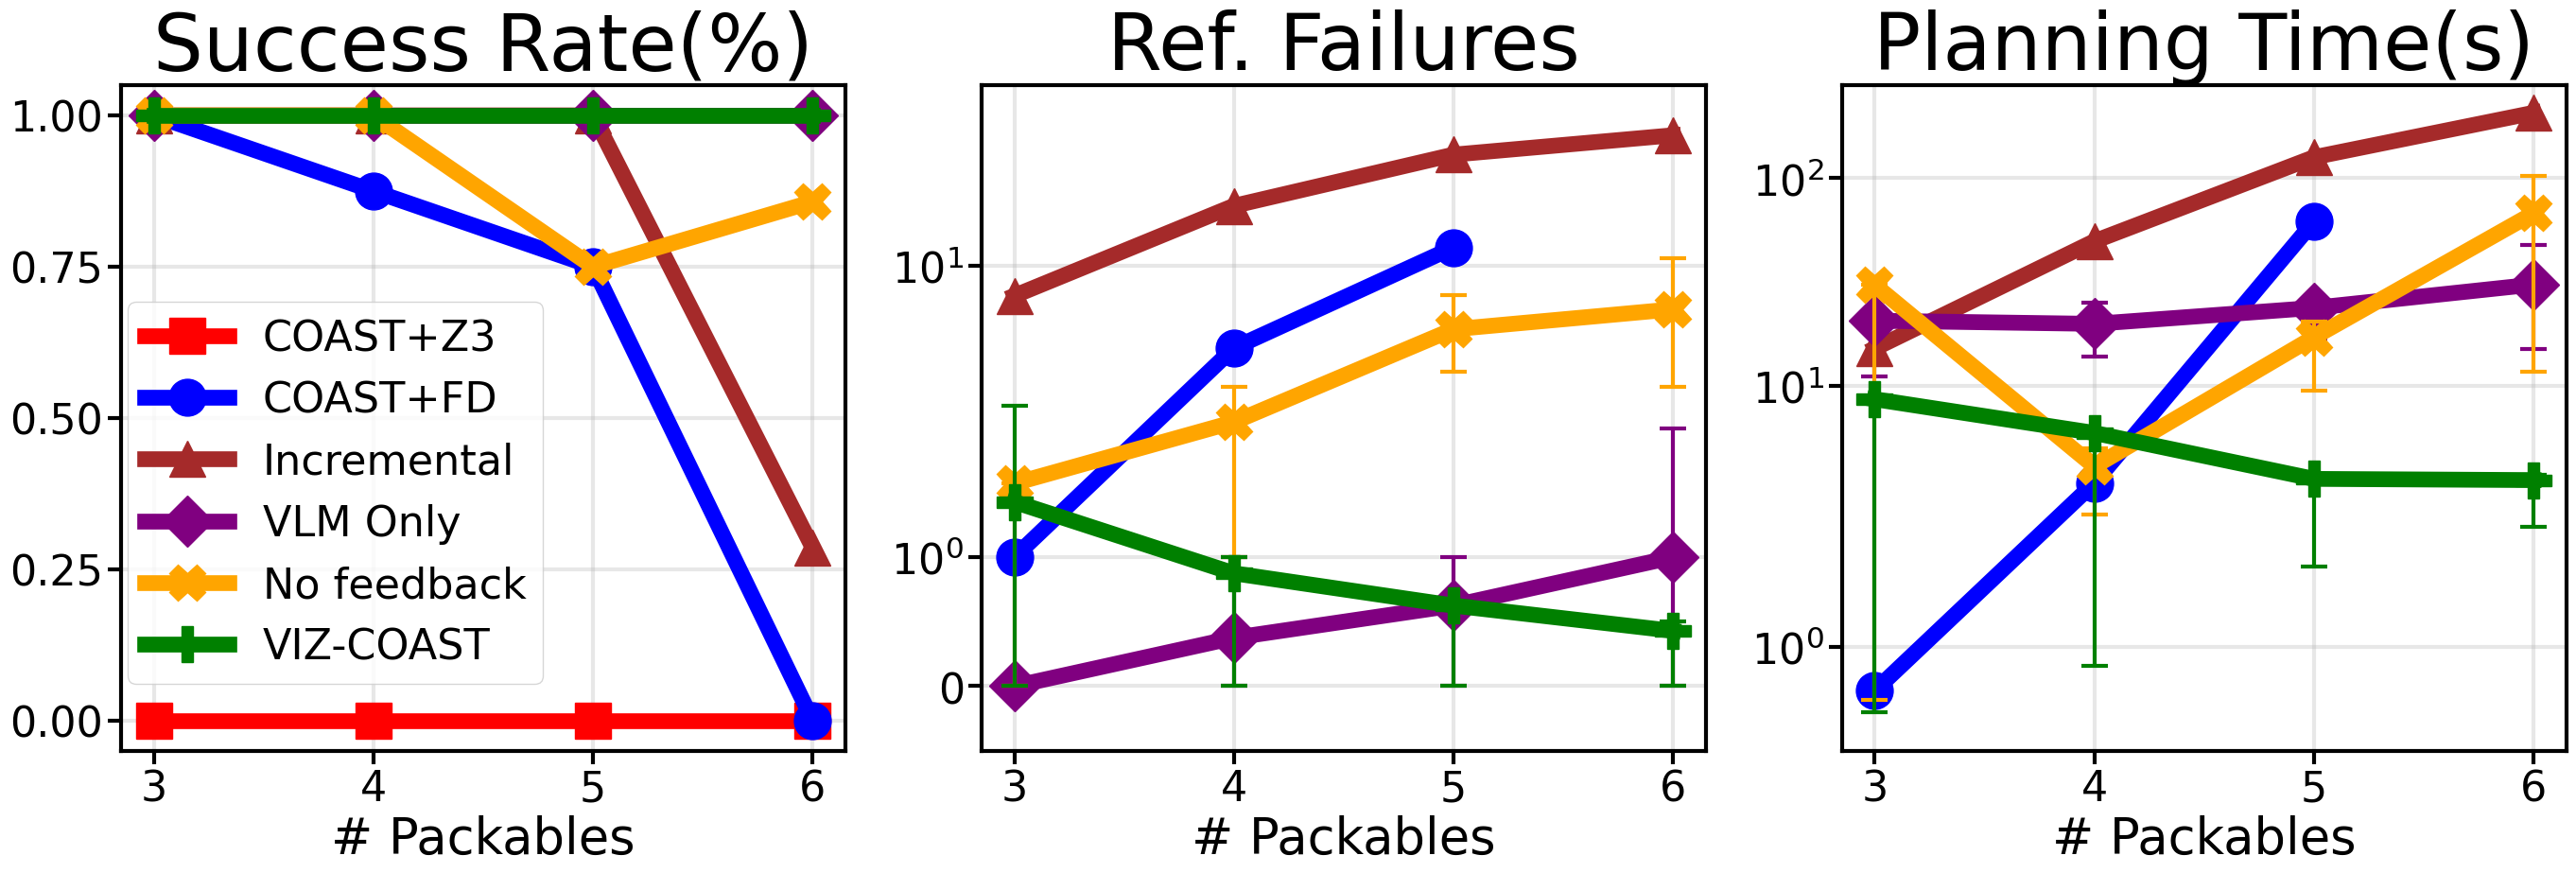

In [ ]:
def get_num_packables(packables):
    return sum(ast.literal_eval(packables))

packing_main_path = 'envs/packing/main_table'
methods = ['coast_z3', 'coast_fd', 'incremental', 'VLMB', 'VIZ-COAST-nofeedback', 'VIZ-COAST']
file_ids = {
    'coast_fd':'0.csv',
    'coast_z3':'0.csv',
    'incremental':'0.csv',
    'VLMB':'0.csv',
    'VIZ-COAST':'0.csv',
    'VIZ-COAST-nofeedback':'0.csv'
}
packing_metrics = compute_full_metrics(packing_main_path, methods, get_num_packables, file_ids=file_ids, global_success=0)
custom_y_bounds = {
    "success_rate": [-0.05, 1.05],
    "ref_failures": [-0.5, 60],
    "avg_planning_time": [0.1, 280]
}
custom_legend_position = {
    "success_rate": (0.01, 0.1),
    "ref_failures": None,
    "avg_planning_time": None
}
plot_stratified_metrics(
    packing_metrics,
    "num_packables",
    custom_y_bounds=custom_y_bounds,
    custom_legend_positions=custom_legend_position,
    linear_scale=["success_rate"],
    metrics=["success_rate", "ref_failures", "avg_planning_time"],
    show_variance={"ref_failures", "avg_planning_time"},
    variance_methods={"VIZ-COAST", "VLMB", "VIZ-COAST-nofeedback"},
    variance_style="errorbar",
    spread_style="percentile"
)

# Cooking

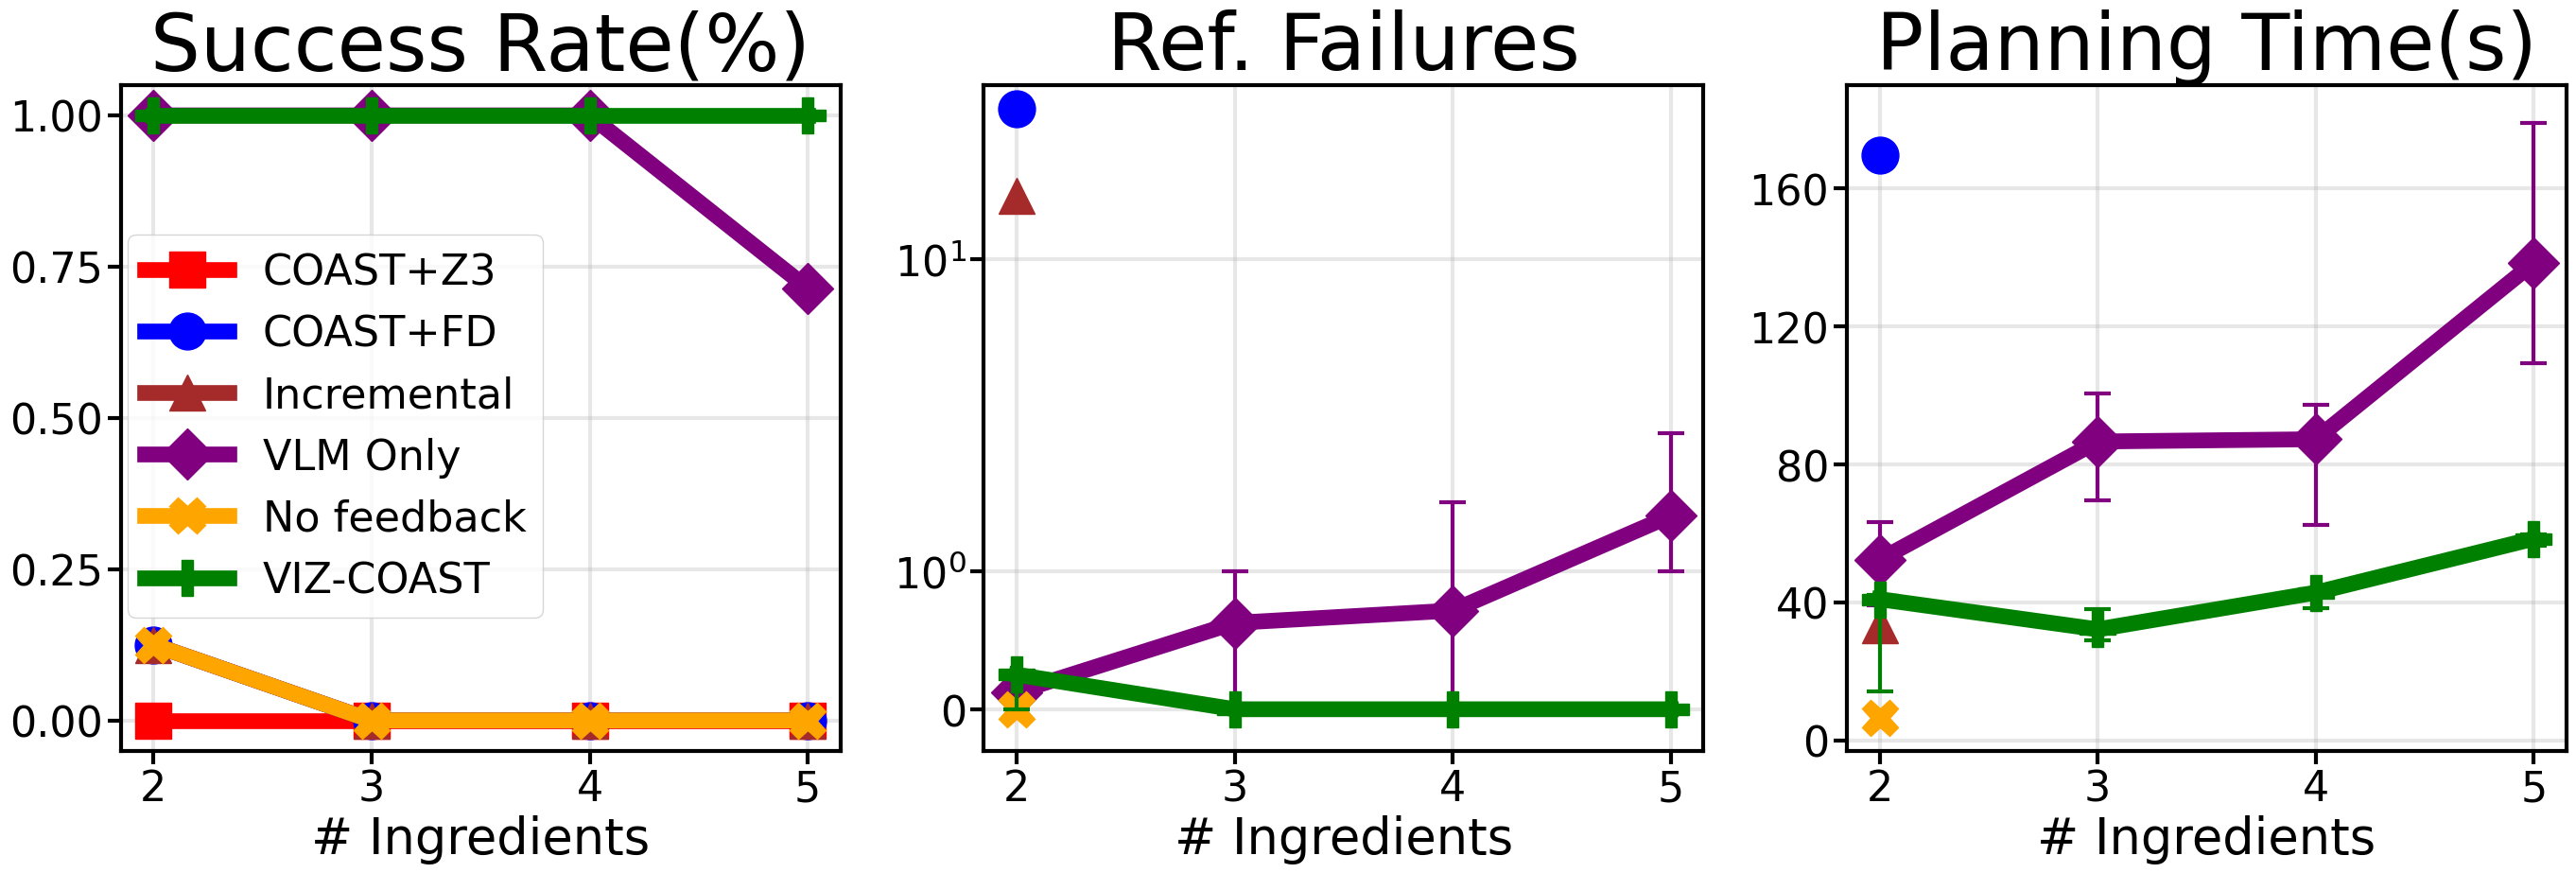

In [ ]:
def get_num_ingredients(num_ingredients):
    # cooking logs ingredients per burner, e.g. "{'left': 2, 'right': 1}"
    # (older runs logged a plain list) -- stratify on the total across burners
    counts = ast.literal_eval(num_ingredients)
    if isinstance(counts, dict):
        counts = counts.values()
    return sum(counts)

cooking_main_path = 'envs/cooking/main_table'
# only the VLM-driven methods have been run on cooking so far
methods = ['coast_z3', 'coast_fd', 'incremental', 'VLMB', 'VIZ-COAST-nofeedback', 'VIZ-COAST']
# methods = ['VLMB', 'VIZ-COAST']
file_ids = {
    'coast_fd':'0.csv',
    'coast_z3':'0.csv',
    'incremental':'0.csv',
    'VLMB':'0.csv',
    'VIZ-COAST':'0.csv',
    'VIZ-COAST-nofeedback':'0.csv'
}
# only 2 methods here, so global_success=2 means "both methods solved the problem"
cooking_metrics = compute_full_metrics(cooking_main_path, methods, get_num_ingredients, file_ids=file_ids, global_success=0)
custom_y_bounds = {
    "success_rate": [-0.05, 1.05],
    "ref_failures": [-0.3, 50],
    "avg_planning_time": [-3, 190]
}
custom_legend_position = {
    "success_rate": (0.01, 0.2),
    "ref_failures": None,
    "avg_planning_time": None,
    "avg_process_time": None
}
plot_stratified_metrics(
    cooking_metrics,
    "num_ingredients",
    custom_y_bounds=custom_y_bounds,
    custom_legend_positions=custom_legend_position,
    linear_scale=["success_rate", "avg_planning_time"],
    # avg_process_time is the grounding time
    metrics=["success_rate", "ref_failures", "avg_planning_time"],
    show_variance={"ref_failures", "avg_planning_time"},
    variance_methods={"VIZ-COAST", "VLMB"},
    variance_style="errorbar",
    spread_style="percentile"
)

# VRM Robustness (VLM table)

In [99]:
# Paper Table I: how consistently the VRM infers constraints that prevent downward
# refinement failure, across VLM providers, models, and reasoning budgets.
#
# The unit here is a *trial*, not a problem: each trial runs VLM_NUM_PROBLEMS sequential
# Blocks problems (4-7 blocks) that share one constraint set, generated once up front and
# updated on each refinement failure (re-prompting threshold K = 1). That is why this
# section does not reuse compute_full_metrics, which aggregates over problems within one
# trial rather than over trials.

vlm_table_path = 'envs/shelf/vlm_table'

# Row order and paper-facing name for each results directory. Directories that are not
# listed still appear, at the bottom, under their raw directory name.
VLM_LABELS = {
    'gemini-3.5-flash_HIGH':     'Gemini3.5-Flash-High',
    'gemini-3.5-flash_MEDIUM':   'Gemini3.5-Flash-Med',
    'gemini-3.5-flash_LOW':      'Gemini3.5-Flash-Low',
    'gemini-3.5-flash-lite_LOW': 'Gemini3.5-Flash-Lite-Low',
    'gpt-5.6-terra_HIGH':        'GPT5.6-Terra-High',
    'gpt-5.6-luna_MEDIUM':       'GPT5.6-Luna-Med',
    'gpt-5.6-luna_LOW':          'GPT5.6-Luna-Low',
    'qwen3.7-plus_MEDIUM':       'Qwen3.7-Plus-Med',
    'qwen3.5-flash_MEDIUM':       'Qwen3.5-Flash-Med',
}

# problems per trial: 4, 5, 6, 7 blocks
VLM_NUM_PROBLEMS = 4


def list_vlm_configs(path):
    # each subdirectory is one (model, reasoning effort) configuration -- the ones named
    # in VLM_LABELS first, in table order, then anything new that has appeared on disk
    on_disk = [d for d in sorted(os.listdir(path))
               if os.path.isdir(os.path.join(path, d)) and not d.startswith('.')]
    ordered = [cfg for cfg in VLM_LABELS if cfg in on_disk]
    return ordered + [cfg for cfg in on_disk if cfg not in VLM_LABELS]


def load_vlm_trials(path, cfg, num_problems=VLM_NUM_PROBLEMS):
    '''
    One row per trial of `cfg`, aggregated over that trial's sequential problems.

    A trial is aborted at its first failure, so it is finished once it has either solved
    all `num_problems` problems or logged a failure. A trial with neither (short, but no
    failure logged) is still running, and is dropped rather than counted as a failure --
    watch the Trials column to see how much of a configuration has actually landed.
    '''
    trials = []
    csv_names = sorted(
        (f for f in os.listdir(os.path.join(path, cfg)) if f.endswith('.csv')),
        key=lambda f: int(f[:-len('.csv')])
    )
    for csv_name in csv_names:
        df = pd.read_csv(os.path.join(path, cfg, csv_name))
        solved = len(df) == num_problems and (df['success'] == 1).all()
        failed = (df['success'] != 1).any()
        if not solved and not failed:
            continue  # still in progress
        trials.append({
            'trial': int(csv_name[:-len('.csv')]),
            'success': solved,
            # one prompt per VRM call: the initial constraint generation, plus one
            # constraint update per refinement failure
            'num_prompts': df['num_prompts'].sum(),
            'prompting': df['prompting'].sum(),
            'ref_failures': df['iterations'].sum(),
        })
    return pd.DataFrame(
        trials, columns=['trial', 'success', 'num_prompts', 'prompting', 'ref_failures']
    )


def compute_vlm_metrics(trials):
    '''
    Success is the fraction of finished trials that solved every problem. Prompting (time
    per constraint update) and Ref. Failures (refinement failures over a whole trial) are
    mean +/- std over the trials that solved every problem, matching the paper's "metrics
    are averaged over runs in which all problems succeeded".
    '''
    solved = trials[trials['success']]
    time_per_update = solved['prompting'] / solved['num_prompts']
    return {
        'trials': len(trials),
        'success': trials['success'].mean() if len(trials) > 0 else float('nan'),
        'prompting_mean': time_per_update.mean(),
        'prompting_std': time_per_update.std(),
        'ref_failures_mean': solved['ref_failures'].mean(),
        'ref_failures_std': solved['ref_failures'].std(),
    }


def compute_vlm_table(path, num_problems=VLM_NUM_PROBLEMS):
    rows = {}
    for cfg in list_vlm_configs(path):
        trials = load_vlm_trials(path, cfg, num_problems=num_problems)
        if len(trials) == 0:
            print(f"{cfg}: no finished trials, skipping")
            continue
        rows[VLM_LABELS.get(cfg, cfg)] = compute_vlm_metrics(trials)
    return pd.DataFrame(rows).T


def format_vlm_table(vlm_table, show_trials=True):
    formatted = pd.DataFrame({
        'Success': vlm_table['success'].map('{:.0%}'.format),
        'Prompting(s)': [f"{mean:.2f} ± {std:.2f}" for mean, std in
                         zip(vlm_table['prompting_mean'], vlm_table['prompting_std'])],
        'Ref. Failures': [f"{mean:.2f} ± {std:.2f}" for mean, std in
                          zip(vlm_table['ref_failures_mean'], vlm_table['ref_failures_std'])],
    }, index=vlm_table.index)
    if show_trials:
        # not a paper column -- a check that every configuration finished the same number
        # of trials before these numbers get quoted
        formatted.insert(0, 'Trials', vlm_table['trials'].astype(int))
    formatted.index.name = 'VLM'
    return formatted


def vlm_table_to_latex(vlm_table):
    '''
    Matches the original paper's Table I formatting: `\\textbf{100\\%}` for a perfect
    success rate (plain otherwise), and `{\\bf mean} \\pm {\\bf std}` on whichever row has
    the best (lowest) Prompting(s) / Ref. Failures mean -- ties bold every tied row.
    '''
    best_prompting = vlm_table['prompting_mean'].min()
    best_ref_failures = vlm_table['ref_failures_mean'].min()

    def fmt_success(success):
        text = f"{success:.0%}".replace('%', r'\%')
        return rf'$\textbf{{{text}}}$' if success == 1.0 else f'${text}$'

    def fmt_pm(mean, std, best):
        if mean == best:
            return f"${{\\bf {mean:.2f}}} \\pm {{\\bf {std:.2f}}}$"
        return f"${mean:.2f} \\pm {std:.2f}$"

    lines = [
        r'\begin{tabular}{lrrr}',
        r'\toprule',
        r'VLM & Success & Prompting(s)& Ref. Failures\\',
        r'\midrule',
    ]
    for name, row in vlm_table.iterrows():
        lines.append(
            f"{name} & {fmt_success(row['success'])} & "
            f"{fmt_pm(row['prompting_mean'], row['prompting_std'], best_prompting)} & "
            f"{fmt_pm(row['ref_failures_mean'], row['ref_failures_std'], best_ref_failures)} \\\\"
        )
    lines += [r'\bottomrule', r'\end{tabular}']
    return '\n'.join(lines)

In [100]:
vlm_table = compute_vlm_table(vlm_table_path)
display(format_vlm_table(vlm_table))
print(vlm_table_to_latex(vlm_table))

,Trials,Success,Prompting(s),Ref. Failures
VLM,,,,
Gemini3.5-Flash-High,20,100%,49.41 ± 8.36,0.70 ± 0.57
Gemini3.5-Flash-Med,20,100%,39.91 ± 9.61,0.55 ± 0.94
Gemini3.5-Flash-Low,20,100%,22.87 ± 4.37,0.10 ± 0.31
Gemini3.5-Flash-Lite-Low,20,100%,6.28 ± 2.20,7.05 ± 8.87
GPT5.6-Terra-High,20,100%,81.17 ± 26.70,0.45 ± 0.51
GPT5.6-Luna-Med,20,100%,55.31 ± 36.85,0.85 ± 1.23
GPT5.6-Luna-Low,18,100%,25.24 ± 9.77,2.22 ± 6.03
Qwen3.7-Plus-Med,20,100%,236.15 ± 84.42,0.35 ± 0.49
Qwen3.5-Flash-Med,22,73%,241.83 ± 108.52,1.38 ± 0.89


\begin{tabular}{lrrr}
\toprule
VLM & Success & Prompting(s)& Ref. Failures\\
\midrule
Gemini3.5-Flash-High & $\textbf{100\%}$ & $49.41 \pm 8.36$ & $0.70 \pm 0.57$ \\
Gemini3.5-Flash-Med & $\textbf{100\%}$ & $39.91 \pm 9.61$ & $0.55 \pm 0.94$ \\
Gemini3.5-Flash-Low & $\textbf{100\%}$ & $22.87 \pm 4.37$ & ${\bf 0.10} \pm {\bf 0.31}$ \\
Gemini3.5-Flash-Lite-Low & $\textbf{100\%}$ & ${\bf 6.28} \pm {\bf 2.20}$ & $7.05 \pm 8.87$ \\
GPT5.6-Terra-High & $\textbf{100\%}$ & $81.17 \pm 26.70$ & $0.45 \pm 0.51$ \\
GPT5.6-Luna-Med & $\textbf{100\%}$ & $55.31 \pm 36.85$ & $0.85 \pm 1.23$ \\
GPT5.6-Luna-Low & $\textbf{100\%}$ & $25.24 \pm 9.77$ & $2.22 \pm 6.03$ \\
Qwen3.7-Plus-Med & $\textbf{100\%}$ & $236.15 \pm 84.42$ & $0.35 \pm 0.49$ \\
Qwen3.5-Flash-Med & $73\%$ & $241.83 \pm 108.52$ & $1.38 \pm 0.89$ \\
\bottomrule
\end{tabular}
